In [71]:
import os
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
path = 'datasets/aog_test'

df_names = ['components.csv', 'fleet_info.csv','maintenance_events.csv', 'sensor_readings.csv']
dfs = {}
for name in df_names:
    dfs[name] = pd.read_csv(os.path.join(path, name))

components, fleet_info, maintenance_events, sensor_readings = dfs.values()

In [73]:
components.head()

,component_id,aircraft_id,component_type,installation_date,status
0,C001,AC014,actuator,2023-08-06,active
1,C002,AC012,bearing,2023-07-11,active
2,C003,AC006,actuator,2023-02-05,replaced
3,C004,AC007,hydraulic_pump,2023-08-04,replaced
4,C005,AC015,bearing,2023-06-07,active


In [74]:
components[components['component_id'] == 'C001'] # FILTER STATUS == 'active'

,component_id,aircraft_id,component_type,installation_date,status
0,C001,AC014,actuator,2023-08-06,active


In [75]:
fleet_info.head() # CALCULATE AGE OF AIRCRAFTS BASED ON MANUFACTURE DATE AND CURRENT DATE

,aircraft_id,aircraft_model,manufacture_year,base_airport,total_flight_hours
0,AC001,E190,2009,LIM,52814
1,AC002,B737-800,2017,SCL,45980
2,AC003,B737-800,2015,SCL,46680
3,AC004,A320,2005,SCL,32501
4,AC005,A320,2010,SCL,54382


In [76]:
sensor_readings.head() # COMPONENTS ARE UNIQUE FOR EACH AIRCRAFT, TEMP, VIBRATION AND PRESSURE SHOULD BE TREATED AS MIN, MAX, MEAN AND STD FOR EACH COMPONENT

,reading_id,component_id,flight_cycle,timestamp,temperature_celsius,vibration_mm_s,pressure_psi
0,1,C001,1,2024-01-01 08:14:00,59.756919,2.815316,1943.090329
1,2,C001,2,2024-01-01 16:48:00,58.976611,2.752847,1958.279957
2,3,C001,3,2024-01-02 00:35:00,60.483151,3.086081,2052.898299
3,4,C001,4,2024-01-02 08:49:00,61.875312,3.336544,2046.006625
4,5,C001,5,2024-01-02 16:37:00,55.742453,3.294884,2013.584800


In [77]:
maintenance_events # UNSCHEDULED IS THE EVENT WE NEED TO PREDICT

,event_id,component_id,flight_cycle,maintenance_type,action,downtime_hours,aircraft_id,event_date
0,1,C017,21.0,scheduled,cleaning,2.0,AC001,2024-01-08 04:00
1,2,C008,97.0,Scheduled,inspection,1.0,AC007,2024-02-02 12:00
2,3,C008,11.0,scheduled,adjustment,5.0,AC007,2024-01-04 20:00
3,4,C014,100.0,Scheduled,lubrication,2.0,AC005,2024-02-03 12:00
4,5,C012,98.0,UNSCHEDULED,replacement,30.0,AC018,2024-02-02 20:00
...,...,...,...,...,...,...,...,...
194,195,C027,18.0,SCHEDULED,inspection,1.0,AC002,2024-01-07 04:00
195,196,C034,46.0,SCHEDULED,inspection,4.0,AC010,2024-01-16 12:00
196,197,C020,4.0,SCHEDULED,adjustment,1.0,AC017,2024-01-02 12:00
197,198,C040,7.0,Scheduled,cleaning,4.0,AC002,2024-01-03 12:00


In [78]:
maintenance_events.info()

<class 'pandas.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   event_id          199 non-null    int64  
 1   component_id      199 non-null    str    
 2   flight_cycle      197 non-null    float64
 3   maintenance_type  199 non-null    str    
 4   action            199 non-null    str    
 5   downtime_hours    199 non-null    float64
 6   aircraft_id       199 non-null    str    
 7   event_date        199 non-null    str    
dtypes: float64(2), int64(1), str(5)
memory usage: 12.6 KB


In [79]:
for name, df in dfs.items():
    print(f"\n{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(df.dtypes.to_string())


components.csv: 50 rows x 5 columns
component_id         str
aircraft_id          str
component_type       str
installation_date    str
status               str

fleet_info.csv: 20 rows x 5 columns
aircraft_id             str
aircraft_model          str
manufacture_year      int64
base_airport            str
total_flight_hours    int64

maintenance_events.csv: 199 rows x 8 columns
event_id              int64
component_id            str
flight_cycle        float64
maintenance_type        str
action                  str
downtime_hours      float64
aircraft_id             str
event_date              str

sensor_readings.csv: 5,015 rows x 7 columns
reading_id               int64
component_id               str
flight_cycle             int64
timestamp                  str
temperature_celsius    float64
vibration_mm_s         float64
pressure_psi           float64


In [80]:
null_pct = pd.concat(
    {name: df.isna().mean().mul(100).round(3) for name, df in dfs.items()}, names=["table", "column"]
).rename("null_%").to_frame()
null_pct

null_%
table                  column                     
components.csv         component_id          0.000
                       aircraft_id           0.000
                       component_type        0.000
                       installation_date     0.000
                       status                0.000
fleet_info.csv         aircraft_id           0.000
                       aircraft_model        0.000
                       manufacture_year      0.000
                       base_airport          0.000
                       total_flight_hours    0.000
maintenance_events.csv event_id              0.000
                       component_id          0.000
                       flight_cycle          1.005
                       maintenance_type      0.000
                       action                0.000
                       downtime_hours        0.000
                       aircraft_id           0.000
                       event_date            0.000
sensor_readings.csv    reading_id            0.000
                       component_id          0.000
                       flight_cycle          0.000
                       timestamp             0.000
                       temperature_celsius   1.994
                       vibration_mm_s        1.994
                       pressure_psi          1.994

## EDA

### Grain (one line per table)
- `fleet_info`: 1 row per `aircraft_id`.
- `components`: 1 row per `component_id`; each component is installed on exactly one `aircraft_id`.
- `sensor_readings`: 1 row per `reading_id`; expected to be 1 row per (`component_id`, `flight_cycle`) — checked below.
- `maintenance_events`: 1 row per `event_id` (one maintenance action on one component at one flight cycle). `maintenance_type == unscheduled` is a **failure**.

In [81]:
SENSORS = ['temperature_celsius', 'vibration_mm_s', 'pressure_psi']
DATE_COLS = ['installation_date', 'timestamp', 'event_date']

grain = {
    'fleet_info.csv': ['aircraft_id'],
    'components.csv': ['component_id'],
    'sensor_readings.csv': ['reading_id'],
    'maintenance_events.csv': ['event_id'],
}
# business key that should also be unique
natural_key = {'sensor_readings.csv': ['component_id', 'flight_cycle']}

summary = []
for name, keys in grain.items():
    df = dfs[name]
    nk = natural_key.get(name)
    summary.append({
        'table': name,
        'rows': len(df),
        'grain': ' + '.join(keys),
        'grain_unique': not df.duplicated(keys).any(),
        'dup_rows_full': df.duplicated().sum(),
        'dup_rows_ignoring_id': df.drop(columns=keys).duplicated().sum(),
        'natural_key': ' + '.join(nk) if nk else '-',
        'natural_key_dups': df.duplicated(nk).sum() if nk else 0,
    })
pd.DataFrame(summary).set_index('table')

,rows,grain,grain_unique,dup_rows_full,dup_rows_ignoring_id,natural_key,natural_key_dups
table,,,,,,,
fleet_info.csv,20,aircraft_id,True,0,0,-,0
components.csv,50,component_id,True,0,0,-,0
sensor_readings.csv,5015,reading_id,True,0,15,component_id + flight_cycle,15
maintenance_events.csv,199,event_id,True,0,0,-,0


In [82]:
# sensor rows that repeat the same (component_id, flight_cycle) — identical except reading_id
sensor_dups = sensor_readings[sensor_readings.duplicated(['component_id', 'flight_cycle'], keep=False)]
print(f"{sensor_readings.duplicated(['component_id', 'flight_cycle']).sum()} extra rows "
      f"across {sensor_dups['component_id'].nunique()} components")
sensor_dups.head(6)

15 extra rows across 11 components


,reading_id,component_id,flight_cycle,timestamp,temperature_celsius,vibration_mm_s,pressure_psi
88,89,C001,89,2024-01-30 16:27:00,63.512205,2.784834,2038.176891
89,90,C001,89,2024-01-30 16:27:00,63.512205,2.784834,2038.176891
930,931,C010,30,2024-01-11 00:03:00,72.508471,3.923121,2926.234299
931,932,C010,30,2024-01-11 00:03:00,72.508471,3.923121,2926.234299
1132,1133,C012,31,2024-01-11 08:10:00,82.123733,5.752392,25.206772
1133,1134,C012,31,2024-01-11 08:10:00,82.123733,5.752392,25.206772


### Nulls

In [83]:
for name, df in dfs.items():
    n = df.isna().sum()
    n = n[n > 0]
    detail = ', '.join(f'{c}={v} ({v / len(df):.1%})' for c, v in n.items()) or 'no nulls'
    print(f'{name}: {detail}')

# do sensor nulls hit the same rows, or one sensor at a time?
print('\nsensor nulls per row:', sensor_readings[SENSORS].isna().sum(axis=1).value_counts().sort_index().to_dict())

components.csv: no nulls
fleet_info.csv: no nulls
maintenance_events.csv: flight_cycle=2 (1.0%)
sensor_readings.csv: temperature_celsius=100 (2.0%), vibration_mm_s=100 (2.0%), pressure_psi=100 (2.0%)

sensor nulls per row: {0: 4720, 1: 290, 2: 5}


### Categorical variables: nunique and values

In [84]:
for name, df in dfs.items():
    cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c not in DATE_COLS]
    print(f'\n=== {name}')
    print(df[cat_cols].nunique().to_string())
    for c in cat_cols:
        if df[c].nunique() <= 10:
            print(f'  {c}: {df[c].value_counts(dropna=False).to_dict()}')


=== components.csv
component_id      50
aircraft_id       19
component_type     5
status             2
  component_type: {'bearing': 13, 'filter': 12, 'actuator': 11, 'hydraulic_pump': 10, 'valve': 4}
  status: {'active': 39, 'replaced': 11}

=== fleet_info.csv
aircraft_id       20
aircraft_model     3
base_airport       3
  aircraft_model: {'B737-800': 8, 'E190': 6, 'A320': 6}
  base_airport: {'LIM': 8, 'BOG': 7, 'SCL': 5}

=== maintenance_events.csv
component_id        51
maintenance_type     6
action               6
aircraft_id         19
  maintenance_type: {'scheduled': 68, 'Scheduled': 60, 'SCHEDULED': 60, 'UNSCHEDULED ': 4, 'Unscheduled': 4, 'unscheduled': 3}
  action: {'inspection': 54, 'adjustment': 48, 'cleaning': 44, 'lubrication': 42, 'major_repair': 7, 'replacement': 4}

=== sensor_readings.csv
component_id    50


`maintenance_type` has 6 spellings of 2 values (case + trailing spaces). Normalize to `scheduled` / `unscheduled`.

In [85]:
before = maintenance_events['maintenance_type'].nunique()
maintenance_events['maintenance_type'] = maintenance_events['maintenance_type'].str.strip().str.lower()
print(f'maintenance_type: {before} -> {maintenance_events["maintenance_type"].nunique()} values')
print(maintenance_events['maintenance_type'].value_counts().to_dict())

maintenance_type: 6 -> 2 values
{'scheduled': 188, 'unscheduled': 11}


### Date ranges and key relationships

In [86]:
for df, col in [(components, 'installation_date'), (sensor_readings, 'timestamp'), (maintenance_events, 'event_date')]:
    df[col] = pd.to_datetime(df[col])
    print(f'{col:18s} {df[col].min()} -> {df[col].max()}')

# orphan keys
print('\ncomponents.aircraft_id not in fleet_info:', set(components['aircraft_id']) - set(fleet_info['aircraft_id']))
print('sensor_readings.component_id not in components:', set(sensor_readings['component_id']) - set(components['component_id']))
print('maintenance_events.component_id not in components:', set(maintenance_events['component_id']) - set(components['component_id']))

# event aircraft must match the aircraft the component is installed on
chk = maintenance_events.merge(components[['component_id', 'aircraft_id']], on='component_id',
                               how='inner', suffixes=('', '_comp'), validate='many_to_one')
mismatch = chk[chk['aircraft_id'] != chk['aircraft_id_comp']]
print(f'events whose aircraft_id differs from the component\'s aircraft: {len(mismatch)}')
display(maintenance_events[~maintenance_events['component_id'].isin(components['component_id'])])
mismatch

installation_date  2022-01-09 00:00:00 -> 2023-08-12 00:00:00
timestamp          2024-01-01 08:00:00 -> 2024-02-03 08:59:00
event_date         2024-01-01 12:00:00 -> 2024-02-03 12:00:00

components.aircraft_id not in fleet_info: set()
sensor_readings.component_id not in components: set()
maintenance_events.component_id not in components: {'C999'}
events whose aircraft_id differs from the component's aircraft: 0


,event_id,component_id,flight_cycle,maintenance_type,action,downtime_hours,aircraft_id,event_date
28,29,C999,50.0,scheduled,inspection,2.0,AC001,2024-01-17 12:00:00


,event_id,component_id,flight_cycle,maintenance_type,action,downtime_hours,aircraft_id,event_date,aircraft_id_comp


### Sensor extreme values

Each sensor has its own unit, and the normal level also depends on the component type (e.g. pressure is ~25 psi on bearings but ~3,000 psi on hydraulic pumps). So extremes are judged **within each component type**, not on the raw pooled values.

Step 1: placeholder / impossible values (999 °C, negative pressure or vibration).

In [87]:
sensor_readings[SENSORS].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_celsius,4915.0,66.332193,27.746541,40.673972,53.341546,61.867469,81.304373,999.000000
vibration_mm_s,4915.0,3.625134,1.816944,1.135324,1.915628,3.240888,5.350224,12.878718
pressure_psi,4915.0,1230.744697,1160.223232,-1.000000,25.846074,314.301790,2030.861573,3177.153871


In [88]:
invalid = pd.DataFrame({
    'temperature_celsius': sensor_readings['temperature_celsius'] >= 999,
    'vibration_mm_s': sensor_readings['vibration_mm_s'] < 0,
    'pressure_psi': sensor_readings['pressure_psi'] < 0,
})
print('invalid values per sensor:', invalid.sum().to_dict())
sensor_readings[invalid.any(axis=1)]

invalid values per sensor: {'temperature_celsius': 3, 'vibration_mm_s': 0, 'pressure_psi': 3}


,reading_id,component_id,flight_cycle,timestamp,temperature_celsius,vibration_mm_s,pressure_psi
2745,2746,C028,36,2024-01-13 00:37:00,61.462613,2.943482,-1.000000
2774,2775,C028,65,2024-01-22 16:16:00,999.000000,2.961834,1962.212135
3509,3510,C035,100,2024-02-03 08:53:00,44.895464,1.420788,-1.000000
3825,3826,C039,15,2024-01-06 00:15:00,999.000000,4.265268,3008.302941
3933,3934,C040,23,2024-01-08 16:40:00,45.650119,1.473104,-1.000000
4782,4783,C048,68,2024-01-23 16:28:00,999.000000,NaN,2972.177467


Step 2: clean working copy `sensors` (raw `sensor_readings` stays untouched):
- drop exact duplicate (`component_id`, `flight_cycle`) rows, logged
- set invalid values to NaN, keep a flag column
- add `component_type`

In [89]:
n0 = len(sensor_readings)
sensors = sensor_readings.drop_duplicates(['component_id', 'flight_cycle']).copy()
print(f'dropped {n0 - len(sensors)} duplicate readings ({n0} -> {len(sensors)})')

sensors['flag_invalid_reading'] = invalid.loc[sensors.index].any(axis=1)
sensors[SENSORS] = sensors[SENSORS].mask(invalid.loc[sensors.index])
print(f'set {int(invalid.loc[sensors.index].sum().sum())} invalid values to NaN')

sensors = sensors.merge(components[['component_id', 'component_type']], on='component_id',
                        how='left', validate='many_to_one')
assert len(sensors) == n0 - sensor_readings.duplicated(['component_id', 'flight_cycle']).sum()

# the scale differs per component type -> pooled stats are meaningless
sensors.groupby('component_type')[SENSORS].agg(['median', 'min', 'max']).round(1)

dropped 15 duplicate readings (5015 -> 5000)
set 6 invalid values to NaN


temperature_celsius              vibration_mm_s             \
                            median   min    max         median  min   max   
component_type                                                              
actuator                      60.1  53.2   74.4            3.0  2.3   6.8   
bearing                       85.1  74.7  101.8            6.0  4.5  12.9   
filter                        45.2  40.7   55.5            1.5  1.1   3.4   
hydraulic_pump                75.0  68.1   89.0            4.0  3.0   9.0   
valve                         55.1  49.8   59.7            2.0  1.6   2.5   

               pressure_psi                  
                     median     min     max  
component_type                               
actuator             1999.0  1791.9  2122.4  
bearing                25.0    21.7    26.6  
filter                299.4   265.3   318.8  
hydraulic_pump       2998.7  2674.9  3177.2  
valve                1500.1  1409.7  1575.9

Step 3: robust z-score per component type: `z = (x - median) / (1.4826 * MAD)`, with |z| > 3.5 as extreme.
Direction follows the domain rule:
- **temperature, vibration**: only *high* values are a problem → flag `z > 3.5`
- **pressure**: a change either way is a problem → flag `|z| > 3.5`

In [90]:
Z_THRESH = 3.5
by_type = sensors['component_type']
for s in SENSORS:
    med = sensors.groupby('component_type')[s].transform('median')
    mad = (sensors[s] - med).abs().groupby(by_type).transform('median')
    sensors[f'z_{s}'] = (sensors[s] - med) / (1.4826 * mad)

extreme = pd.DataFrame({
    'temperature_high': sensors['z_temperature_celsius'] > Z_THRESH,
    'vibration_high': sensors['z_vibration_mm_s'] > Z_THRESH,
    'pressure_high': sensors['z_pressure_psi'] > Z_THRESH,
    'pressure_low': sensors['z_pressure_psi'] < -Z_THRESH,
})
sensors['flag_extreme'] = extreme.any(axis=1)

counts = extreme.groupby(by_type).sum()
counts['any_extreme'] = sensors.groupby('component_type')['flag_extreme'].sum()
counts['readings'] = by_type.value_counts()
counts.loc['TOTAL'] = counts.sum()
counts

,temperature_high,vibration_high,pressure_high,pressure_low,any_extreme,readings
component_type,,,,,,
actuator,24,49,0,11,49,1100
bearing,17,33,0,11,35,1300
filter,34,62,0,21,64,1200
hydraulic_pump,21,30,0,10,31,1000
valve,0,0,0,0,0,400
TOTAL,96,174,0,53,179,5000


In [91]:
# most extreme readings per sensor (pressure ranked by |z|)
for s in SENSORS:
    z = sensors[f'z_{s}']
    rank = z.abs() if s == 'pressure_psi' else z
    print(f'\n--- {s}')
    display(sensors.loc[rank.nlargest(5).index,
                        ['component_id', 'component_type', 'flight_cycle', s, f'z_{s}']].round(2))


--- temperature_celsius


,component_id,component_type,flight_cycle,temperature_celsius,z_temperature_celsius
599,C006,actuator,100,74.41,7.82
2999,C030,filter,100,55.55,6.89
2199,C022,filter,100,55.30,6.73
3958,C040,filter,59,54.95,6.49
294,C003,actuator,95,71.93,6.46



--- vibration_mm_s


,component_id,component_type,flight_cycle,vibration_mm_s,z_vibration_mm_s
2298,C023,actuator,99,6.83,15.49
599,C006,actuator,100,6.77,15.25
2299,C023,actuator,100,6.63,14.67
294,C003,actuator,95,6.53,14.25
391,C004,hydraulic_pump,92,9.03,13.95



--- pressure_psi


,component_id,component_type,flight_cycle,pressure_psi,z_pressure_psi
3789,C038,bearing,90,21.71,-6.40
2198,C022,filter,99,265.34,-5.52
2192,C022,filter,93,266.44,-5.34
2997,C030,filter,98,267.05,-5.24
4669,C047,hydraulic_pump,70,2674.86,-5.04


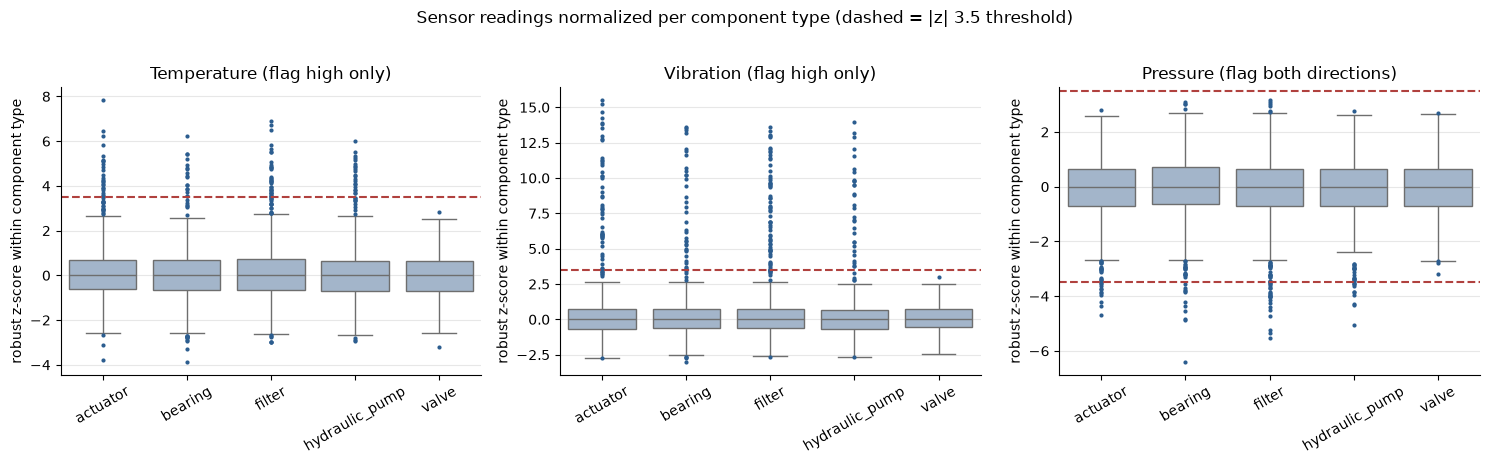

In [92]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
titles = {'temperature_celsius': 'Temperature (flag high only)',
          'vibration_mm_s': 'Vibration (flag high only)',
          'pressure_psi': 'Pressure (flag both directions)'}
order = sorted(sensors['component_type'].unique())
for ax, s in zip(axes, SENSORS):
    sns.boxplot(data=sensors, x='component_type', y=f'z_{s}', order=order, ax=ax,
                color='#9db4d0', linewidth=1, fliersize=3, flierprops={'markerfacecolor': '#2c5d8f', 'markeredgecolor': 'none'})
    ax.axhline(Z_THRESH, color='#b0413e', ls='--', lw=1.5)
    if s == 'pressure_psi':
        ax.axhline(-Z_THRESH, color='#b0413e', ls='--', lw=1.5)
    ax.set_title(titles[s])
    ax.set_xlabel('')
    ax.set_ylabel('robust z-score within component type')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)
    sns.despine(ax=ax)
fig.suptitle(f'Sensor readings normalized per component type (dashed = |z| {Z_THRESH} threshold)', y=1.02)
plt.tight_layout()
plt.show()

### Failures (unscheduled maintenance)

In [93]:
is_failure = maintenance_events['maintenance_type'] == 'unscheduled'
failures = (maintenance_events[is_failure]
            .merge(components[['component_id', 'component_type', 'status']], on='component_id',
                   how='left', validate='many_to_one')
            .merge(fleet_info[['aircraft_id', 'aircraft_model', 'base_airport']], on='aircraft_id',
                   how='left', validate='many_to_one'))
assert len(failures) == is_failure.sum()

print(f'Failures: {len(failures)} of {len(maintenance_events)} events ({is_failure.mean():.1%})')
print(f'Components that failed: {failures["component_id"].nunique()} of {components["component_id"].nunique()}')
print(f'Aircraft with a failure: {failures["aircraft_id"].nunique()} of {fleet_info["aircraft_id"].nunique()}')
print('Failures per component (max):', failures['component_id'].value_counts().max())

pd.concat({c: failures[c].value_counts() for c in ['action', 'component_type', 'aircraft_model', 'base_airport']},
          names=['by', 'value']).rename('failures').to_frame()

Failures: 11 of 199 events (5.5%)
Components that failed: 11 of 50
Aircraft with a failure: 8 of 20
Failures per component (max): 1


failures
by             value                   
action         major_repair           7
               replacement            4
component_type filter                 4
               actuator               3
               bearing                2
               hydraulic_pump         2
aircraft_model A320                   5
               B737-800               4
               E190                   2
base_airport   LIM                    5
               BOG                    4
               SCL                    2

In [94]:
# failure rate by component type
rate = pd.DataFrame({
    'components': components['component_type'].value_counts(),
    'failures': failures['component_type'].value_counts(),
}).fillna(0).astype(int)
rate['failure_rate'] = (rate['failures'] / rate['components']).round(2)
display(rate.sort_values('failure_rate', ascending=False))

# failures per aircraft
display(failures['aircraft_id'].value_counts().rename('failures').to_frame().T)

# downtime cost: failures vs scheduled work
maintenance_events.groupby('maintenance_type')['downtime_hours'].agg(['count', 'sum', 'mean', 'median', 'max'])

,components,failures,failure_rate
component_type,,,
filter,12,4,0.33
actuator,11,3,0.27
hydraulic_pump,10,2,0.20
bearing,13,2,0.15
valve,4,0,0.00


aircraft_id,AC007,AC018,AC013,AC006,AC012,AC002,AC005,AC016
failures,3,2,1,1,1,1,1,1


,count,sum,mean,median,max
maintenance_type,,,,,
scheduled,188,567.0,3.015957,3.0,5.0
unscheduled,11,405.0,36.818182,35.0,69.0


In [95]:
# does components.status == 'replaced' line up with failures?
pd.crosstab(components['status'],
            components['component_id'].isin(failures['component_id']).map({True: 'failed', False: 'no failure'}),
            margins=True)

component_id,failed,no failure,All
status,,,
active,0,39,39
replaced,11,0,11
All,11,39,50


In [96]:
# leading signal check: extreme readings on components that failed vs. did not
per_comp = extreme.groupby(sensors['component_id']).sum()
per_comp['any_extreme'] = sensors.groupby('component_id')['flag_extreme'].sum()
per_comp['failed'] = per_comp.index.isin(failures['component_id'])
per_comp.groupby('failed').agg(['mean', 'sum']).round(2)

temperature_high     vibration_high      pressure_high      \
                   mean sum           mean  sum          mean sum   
failed                                                              
False              0.03   1           0.00    0           0.0   0   
True               8.64  95          15.82  174           0.0   0   

       pressure_low     any_extreme       
               mean sum        mean  sum  
failed                                    
False          0.03   1        0.05    2  
True           4.73  52       16.09  177

In [97]:
# how many cycles before the failure do the extremes appear?
lead = (sensors.loc[sensors['flag_extreme'], ['component_id', 'flight_cycle']]
        .merge(failures[['component_id', 'flight_cycle']].rename(columns={'flight_cycle': 'fail_cycle'}),
               on='component_id', how='inner', validate='many_to_one'))
lead['cycles_before_failure'] = lead['fail_cycle'] - lead['flight_cycle']
print(f'extreme readings after the failure cycle: {(lead["cycles_before_failure"] < 0).sum()}')
lead['cycles_before_failure'].describe().round(1)

extreme readings after the failure cycle: 0


count    177.0
mean       7.8
std        5.1
min        0.0
25%        4.0
50%        8.0
75%       12.0
max       26.0
Name: cycles_before_failure, dtype: float64

### Findings

| # | Issue | Decision |
|---|---|---|
| 1 | `sensor_readings`: 15 exact duplicate (`component_id`, `flight_cycle`) rows on 11 components | dropped in `sensors` (5015 → 5000), logged |
| 2 | Placeholder values: 3 × `temperature = 999`, 3 × `pressure = -1` | set to NaN in `sensors`, `flag_invalid_reading` kept |
| 3 | Sensor nulls: 100 per sensor (2%), mostly one sensor per row | kept as NaN for now |
| 4 | `maintenance_type` has 6 spellings (case + trailing space) | normalized to `scheduled` / `unscheduled` |
| 5 | `maintenance_events`: `C999` (event 29) is not in `components` | orphan; exclude when joining to components |
| 6 | `maintenance_events.flight_cycle`: 2 nulls | keep; `event_date` is complete |
| 7 | Sensor scales differ per component type (pressure 25 psi on bearings vs 3,000 psi on pumps) | extremes judged with robust z-score **within component type** |
| 8 | All pressure extremes are **drops**; none are increases | keep two-sided rule, but low pressure is what shows up |
| 9 | **11 failures** (5.5% of events), 11 distinct components, 8 aircraft; avg downtime 36.8 h vs 3.0 h scheduled | target = unscheduled event |
| 10 | Almost all extreme readings (177 of 179) are on components that later failed, and they appear 0–26 cycles before the failure (median 8), never after | strong leading signal; sensor features must only use readings **before** the prediction cycle |
| 11 | `components.status == 'replaced'` matches the 11 failed components exactly | **leakage**: it is the outcome, not a feature |
| 12 | Data window is short (2024-01-01 → 2024-02-03, ~100 cycles per component) and many failures happen at cycle 100 | small sample; split by time/component, not randomly |

## Target: `will_fail_within_30_cycle`

**Grain:** 1 row per (`component_id`, `flight_cycle`), i.e. one row per sensor reading in `sensors`.
**Prediction time:** right after the reading at cycle `c`. Features may only use readings at cycles `<= c`.

**Definition.** `cycles_to_failure = next_failure_cycle - c`, where `next_failure_cycle` is the first unscheduled event on that component at cycle `>= c`.
- **1**: `cycles_to_failure <= 30` (the failure happens in cycles `c … c+30`)
- **0**: no failure in that range, **and** the whole range is recorded (`c + 30 <= last recorded cycle`)
- **unknown (NA)**: no failure seen, but the range runs past the end of the data, so we can't tell. These rows are kept but must not be used for training or evaluation.

Choices:
- **The failure cycle itself counts as 1** (`cycles_to_failure = 0`). The failure is logged *after* that cycle's reading (checked below), so at prediction time it hasn't happened yet.
- **Readings after a failure restart the history.** The component was repaired or replaced, and its readings return to normal. They are labelled with the same rule. With no second failure, they come out 0 or unknown.

In [98]:
HORIZON = 30

fail_cycles = (maintenance_events.loc[maintenance_events['maintenance_type'] == 'unscheduled',
                                      ['component_id', 'flight_cycle', 'event_date']]
               .rename(columns={'flight_cycle': 'next_failure_cycle', 'event_date': 'failure_date'}))
assert fail_cycles['next_failure_cycle'].notna().all(), 'every failure needs a flight_cycle'
fail_cycles['next_failure_cycle'] = fail_cycles['next_failure_cycle'].astype('int64')

# the failure is logged after the reading taken at the same cycle -> that reading is a valid "before" point
same_cycle = fail_cycles.merge(sensors[['component_id', 'flight_cycle', 'timestamp']],
                               left_on=['component_id', 'next_failure_cycle'],
                               right_on=['component_id', 'flight_cycle'], how='left', validate='one_to_one')
print(f"failures logged after that cycle's reading: "
      f"{(same_cycle['failure_date'] > same_cycle['timestamp']).sum()} of {len(same_cycle)}")

failures logged after that cycle's reading: 11 of 11


In [99]:
# last recorded cycle per component = end of what we can observe
last_cycle = sensors.groupby('component_id')['flight_cycle'].max().rename('last_recorded_cycle')
print('last recorded cycle per component:', last_cycle.value_counts().to_dict())

base = sensors[['component_id', 'flight_cycle', 'reading_id', 'timestamp', 'component_type']]

# for each reading, the next failure at or after its cycle, on the same component
target = pd.merge_asof(
    base.sort_values('flight_cycle'),
    fail_cycles[['component_id', 'next_failure_cycle']].sort_values('next_failure_cycle'),
    left_on='flight_cycle', right_on='next_failure_cycle', by='component_id',
    direction='forward', allow_exact_matches=True,
).merge(last_cycle, on='component_id', how='left', validate='many_to_one')

assert len(target) == len(sensors), 'row count changed'
assert not target.duplicated(['component_id', 'flight_cycle']).any(), 'grain not unique'

target['cycles_to_failure'] = target['next_failure_cycle'] - target['flight_cycle']
fails_soon = target['cycles_to_failure'] <= HORIZON            # NaN (no next failure) -> False
horizon_seen = target['flight_cycle'] + HORIZON <= target['last_recorded_cycle']

target['will_fail_within_30_cycle'] = pd.Series(pd.NA, index=target.index, dtype='Int8')
target.loc[fails_soon, 'will_fail_within_30_cycle'] = 1
target.loc[~fails_soon & horizon_seen, 'will_fail_within_30_cycle'] = 0

target['tgt_label_reason'] = np.select(
    [fails_soon, horizon_seen],
    ['failure_within_30', 'no_failure_full_window'],
    default='unknown_window_past_end',
)
target = target.sort_values(['component_id', 'flight_cycle']).reset_index(drop=True)
target.head()

last recorded cycle per component: {100: 50}


,component_id,flight_cycle,reading_id,timestamp,component_type,next_failure_cycle,last_recorded_cycle,cycles_to_failure,will_fail_within_30_cycle,tgt_label_reason
0,C001,1,1,2024-01-01 08:14:00,actuator,NaN,100,NaN,0,no_failure_full_window
1,C001,2,2,2024-01-01 16:48:00,actuator,NaN,100,NaN,0,no_failure_full_window
2,C001,3,3,2024-01-02 00:35:00,actuator,NaN,100,NaN,0,no_failure_full_window
3,C001,4,4,2024-01-02 08:49:00,actuator,NaN,100,NaN,0,no_failure_full_window
4,C001,5,5,2024-01-02 16:37:00,actuator,NaN,100,NaN,0,no_failure_full_window


### Class balance

In [100]:
lbl = target['will_fail_within_30_cycle']
known = lbl.notna()

overall = pd.DataFrame({
    'rows': lbl.value_counts(dropna=False).rename(index={pd.NA: 'unknown'}),
})
overall['% of all rows'] = (overall['rows'] / len(target) * 100).round(1)
overall['% of known rows'] = (overall['rows'] / known.sum() * 100).where(overall.index != 'unknown').round(1)
display(overall)

print(f'usable (known) rows: {known.sum()} of {len(target)}  |  dropped as unknown: {(~known).sum()}')
print(f'positive rate among known rows: {lbl[known].mean():.1%}  ->  about 1 positive per {1 / lbl[known].mean():.1f} rows')
print(f'components with at least one positive row: {target.loc[lbl == 1, "component_id"].nunique()} of {target["component_id"].nunique()}')
print(target['tgt_label_reason'].value_counts().to_dict())

,rows,% of all rows,% of known rows
will_fail_within_30_cycle,,,
0,3407,68.1,90.9
unknown,1252,25.0,<NA>
1,341,6.8,9.1


usable (known) rows: 3748 of 5000  |  dropped as unknown: 1252
positive rate among known rows: 9.1%  ->  about 1 positive per 11.0 rows
components with at least one positive row: 11 of 50
{'no_failure_full_window': 3407, 'unknown_window_past_end': 1252, 'failure_within_30': 341}


In [101]:
# balance by component type (known rows only)
by_type = (target[known].groupby('component_type')['will_fail_within_30_cycle']
           .agg(known_rows='size', positives='sum'))
by_type['positive_rate'] = (by_type['positives'] / by_type['known_rows']).round(3)
by_type['components_failed'] = target[lbl == 1].groupby('component_type')['component_id'].nunique()
by_type.fillna({'components_failed': 0}).astype({'components_failed': int})

,known_rows,positives,positive_rate,components_failed
component_type,,,,
actuator,855,93,0.109,3
bearing,968,62,0.064,2
filter,918,124,0.135,4
hydraulic_pump,727,62,0.085,2
valve,280,0,0.0,0


In [102]:
# sanity checks on the label
pos = target[lbl == 1]
print('cycles_to_failure among positives:', pos['cycles_to_failure'].min(), '->', pos['cycles_to_failure'].max())
print('positive rows per failed component:', pos.groupby('component_id').size().describe()[['min', 'max', 'mean']].round(1).to_dict())
print('unknown rows start at cycle:', target.loc[~known, 'flight_cycle'].min())
# example: C047 fails at cycle 75, then restarts -> 0 / 1 / unknown boundaries
c047 = target[target['component_id'] == 'C047']
c047[c047['flight_cycle'].isin([43, 44, 45, 46, 75, 76, 77])][
    ['component_id', 'flight_cycle', 'next_failure_cycle', 'cycles_to_failure', 'will_fail_within_30_cycle', 'tgt_label_reason']]

cycles_to_failure among positives: 0.0 -> 30.0
positive rows per failed component: {'min': 31.0, 'max': 31.0, 'mean': 31.0}
unknown rows start at cycle: 71


,component_id,flight_cycle,next_failure_cycle,cycles_to_failure,will_fail_within_30_cycle,tgt_label_reason
4642,C047,43,75.0,32.0,0,no_failure_full_window
4643,C047,44,75.0,31.0,0,no_failure_full_window
4644,C047,45,75.0,30.0,1,failure_within_30
4645,C047,46,75.0,29.0,1,failure_within_30
4674,C047,75,75.0,0.0,1,failure_within_30
4675,C047,76,NaN,NaN,<NA>,unknown_window_past_end
4676,C047,77,NaN,NaN,<NA>,unknown_window_past_end


**Notes on this target**
- Positives come from only 11 components (about 31 rows each). Rows from the same component are strongly correlated, so the real sample size is closer to 11 failures than to the row count. Split train/test **by component** (or by time), never randomly by row.
- The last 30 cycles (71–100) of every component without a failure in that range are unknown: 1,252 rows, 25% of the data. Collecting more cycles would shrink this.
- `next_failure_cycle`, `cycles_to_failure` and `tgt_label_reason` are label helpers, **not features** (they look into the future).

## Leakage check: single-feature AUC

Each candidate column is scored on its own against `will_fail_within_30_cycle` (known rows only). On a hard problem with ~11 failures, one column that almost perfectly separates the classes is more likely a leak or a design artefact than a real signal.

- `strength` = max(AUC, 1 − AUC), so a column that works "backwards" scores high too.
- `null_flag_strength`: the same test on "is this value missing?". Missingness can leak as well (e.g. `next_failure_cycle` is missing exactly when no failure follows).
- **SUSPECT** ≥ 0.9, **strong: check** ≥ 0.75.
- The label helpers (`next_failure_cycle`, `cycles_to_failure`) are included on purpose as a **positive control**: if the check doesn't flag them, it's broken.
- Text columns are scored by each category's positive rate (in-sample, so slightly optimistic). IDs are skipped: a high score there only means memorising components.

This only catches **strong** leaks. A leaking column with a weak signal (e.g. an end-of-data snapshot) scores ~0.5 and passes. Those have to be excluded by reasoning about *when* each value is known.

In [103]:
from sklearn.metrics import roc_auc_score

# every column we could join at the target grain (known labels only)
leak = (target.loc[known, ['component_id', 'flight_cycle', 'will_fail_within_30_cycle',
                           'next_failure_cycle', 'cycles_to_failure', 'last_recorded_cycle']]
        .merge(sensors.drop(columns=['reading_id', 'component_type']), on=['component_id', 'flight_cycle'],
               how='left', validate='one_to_one')
        .merge(components, on='component_id', how='left', validate='many_to_one')
        .merge(fleet_info, on='aircraft_id', how='left', validate='many_to_one'))
assert len(leak) == known.sum()
y_leak = leak.pop('will_fail_within_30_cycle').astype(int)
leak = leak.drop(columns=['component_id', 'aircraft_id'])  # ids: a high AUC would only mean memorising components

def as_number(s):
    """Dates -> days, booleans -> 0/1, text -> positive rate of each category (in-sample, so a bit optimistic)."""
    if pd.api.types.is_datetime64_any_dtype(s):
        return (s - s.min()).dt.total_seconds() / 86400
    if pd.api.types.is_numeric_dtype(s) or pd.api.types.is_bool_dtype(s):
        return s.astype(float)
    return s.map(y_leak.groupby(s).mean())

rows = []
for c in leak:
    x = as_number(leak[c])
    ok = x.notna()
    auc = roc_auc_score(y_leak[ok], x[ok]) if y_leak[ok].nunique() == 2 else np.nan
    null_auc = roc_auc_score(y_leak, x.isna()) if x.isna().any() else np.nan
    rows.append({'feature': c, 'null_%': round(x.isna().mean() * 100, 1), 'auc': auc,
                 'strength': max(auc, 1 - auc), 'null_flag_strength': max(null_auc, 1 - null_auc)})

LEAK_NOTES = {
    'next_failure_cycle': 'label helper (future): positive control',
    'cycles_to_failure': 'label helper (future): positive control',
    'last_recorded_cycle': 'end of the data window: not known at prediction time',
    'status': "end-of-data snapshot: 'replaced' = failed (finding 11)",
    'total_flight_hours': 'end-of-data snapshot: includes hours flown after the reading',
    'flight_cycle': 'censoring artefact: only failing components keep labelled rows after cycle 70',
    'timestamp': 'same as flight_cycle (time runs with the cycle)',
    'z_temperature_celsius': 'real drift signal, but type median/MAD use all cycles: refit on train only',
    'z_vibration_mm_s': 'real drift signal, but type median/MAD use all cycles: refit on train only',
    'z_pressure_psi': 'real drift signal, but type median/MAD use all cycles: refit on train only',
    'flag_extreme': 'built from the z-scores (same caveat)',
}
auc_table = pd.DataFrame(rows).set_index('feature')
worst = auc_table[['strength', 'null_flag_strength']].max(axis=1)
auc_table['verdict'] = np.select([worst >= 0.9, worst >= 0.75], ['SUSPECT', 'strong: check'], default='ok')
auc_table['note'] = auc_table.index.map(LEAK_NOTES).fillna('')
auc_table = auc_table.loc[worst.sort_values(ascending=False).index]

print(f'{len(leak)} rows, {y_leak.sum()} positives ({y_leak.mean():.1%})')
with pd.option_context('display.max_colwidth', 90):
    display(auc_table.round(3))

3748 rows, 341 positives (9.1%)


,null_%,auc,strength,null_flag_strength,verdict,note
feature,,,,,,
cycles_to_failure,73.1,0.000,1.000,0.902,SUSPECT,label helper (future): positive control
timestamp,0.0,0.949,0.949,NaN,SUSPECT,same as flight_cycle (time runs with the cycle)
flight_cycle,0.0,0.949,0.949,NaN,SUSPECT,censoring artefact: only failing components keep labelled rows after cycle 70
next_failure_cycle,73.1,0.451,0.549,0.902,SUSPECT,label helper (future): positive control
status,0.0,0.901,0.901,NaN,SUSPECT,end-of-data snapshot: 'replaced' = failed (finding 11)
z_vibration_mm_s,1.8,0.855,0.855,0.503,strong: check,"real drift signal, but type median/MAD use all cycles: refit on train only"
z_pressure_psi,2.0,0.150,0.850,0.501,strong: check,"real drift signal, but type median/MAD use all cycles: refit on train only"
z_temperature_celsius,2.0,0.845,0.845,0.507,strong: check,"real drift signal, but type median/MAD use all cycles: refit on train only"
flag_extreme,0.0,0.759,0.759,NaN,strong: check,built from the z-scores (same caveat)


**Leakage decisions**

| Column | Strength | Decision |
|---|---|---|
| `cycles_to_failure`, `next_failure_cycle` | 1.00 / 0.90 (via nulls) | label helpers; flagged as expected, so the check works. Never features. |
| `flight_cycle`, `timestamp` | 0.95 | **exclude**: high only because rows after cycle 70 stay labelled only on failing components (censoring), not because age predicts failure |
| `status` | 0.90 | **exclude**: end-of-data outcome (`replaced` = failed) |
| `total_flight_hours`, `last_recorded_cycle` | ~0.5 | **exclude anyway**: not known at prediction time, even though the AUC doesn't flag them |
| `z_*` sensor scores, `flag_extreme` | 0.76–0.86 | **keep**: the sensors drift before failure (finding 10). The per-type median/MAD are computed on all cycles, so refit them on training data only when modeling |
| raw sensors, `component_type`, aircraft attributes, `installation_date` | 0.50–0.62 | ok |